# Monte Carlo RTP Convergence

Phases 2 and 3 showed that Monte Carlo error shrinks roughly as `1/sqrt(n)` using a few sampled figures (5.05% error at 10K spins, 0.32% at 100K and 0.10% at 1M). This notebook runs one long simulation, tracks the running RTP estimate as spins accumulate, and plots the convergence funnel against a theoretical standard-error band.

In [1]:
import sys
from pathlib import Path


def find_repo_root(start: Path) -> Path:
    current = start.resolve()
    while not (current / "engine").is_dir():
        if current.parent == current:
            raise RuntimeError("could not locate repo root (no engine/ found)")
        current = current.parent
    return current


REPO_ROOT = find_repo_root(Path.cwd())
sys.path.insert(0, str(REPO_ROOT))

%matplotlib inline
import random

import matplotlib.pyplot as plt
import numpy as np

from analytics.rtp import exact_rtp
from engine.config import load_game_config
from simulation.simulate import run_spins

## Exact RTP (from Phase 2)

The exact value the Monte Carlo estimate should converge to.

In [2]:
machine = load_game_config(str(REPO_ROOT / "configs" / "default_game.json"))
exact = exact_rtp(machine)
print(f"Exact RTP: {exact:.4%}")

Exact RTP: 98.9785%


## One long simulation with a running average

Instead of running many independent trials at each sample size, this runs a single 2,000,000-spin simulation and computes the cumulative mean payout after every spin, which is how a running RTP estimate evolves as it updates spin by spin.

In [3]:
NUM_SPINS = 2_000_000
batch = run_spins(machine, NUM_SPINS, bet=1.0, rng=random.Random(7))

payouts = np.array(batch.payouts)
spin_counts = np.arange(1, NUM_SPINS + 1)
cumulative_mean = np.cumsum(payouts) / spin_counts

overall_std = payouts.std()
standard_error = overall_std / np.sqrt(spin_counts)

print(f"Final estimate after {NUM_SPINS:,} spins: {cumulative_mean[-1]:.4%}")

Final estimate after 2,000,000 spins: 98.9568%


## The convergence funnel

The shaded band is the theoretical 95% confidence interval at each sample size (`exact +/- 1.96 * std_dev/sqrt(n)`). It comes from the standard-error formula rather than being fit to this run, and the running estimate should mostly stay inside it.

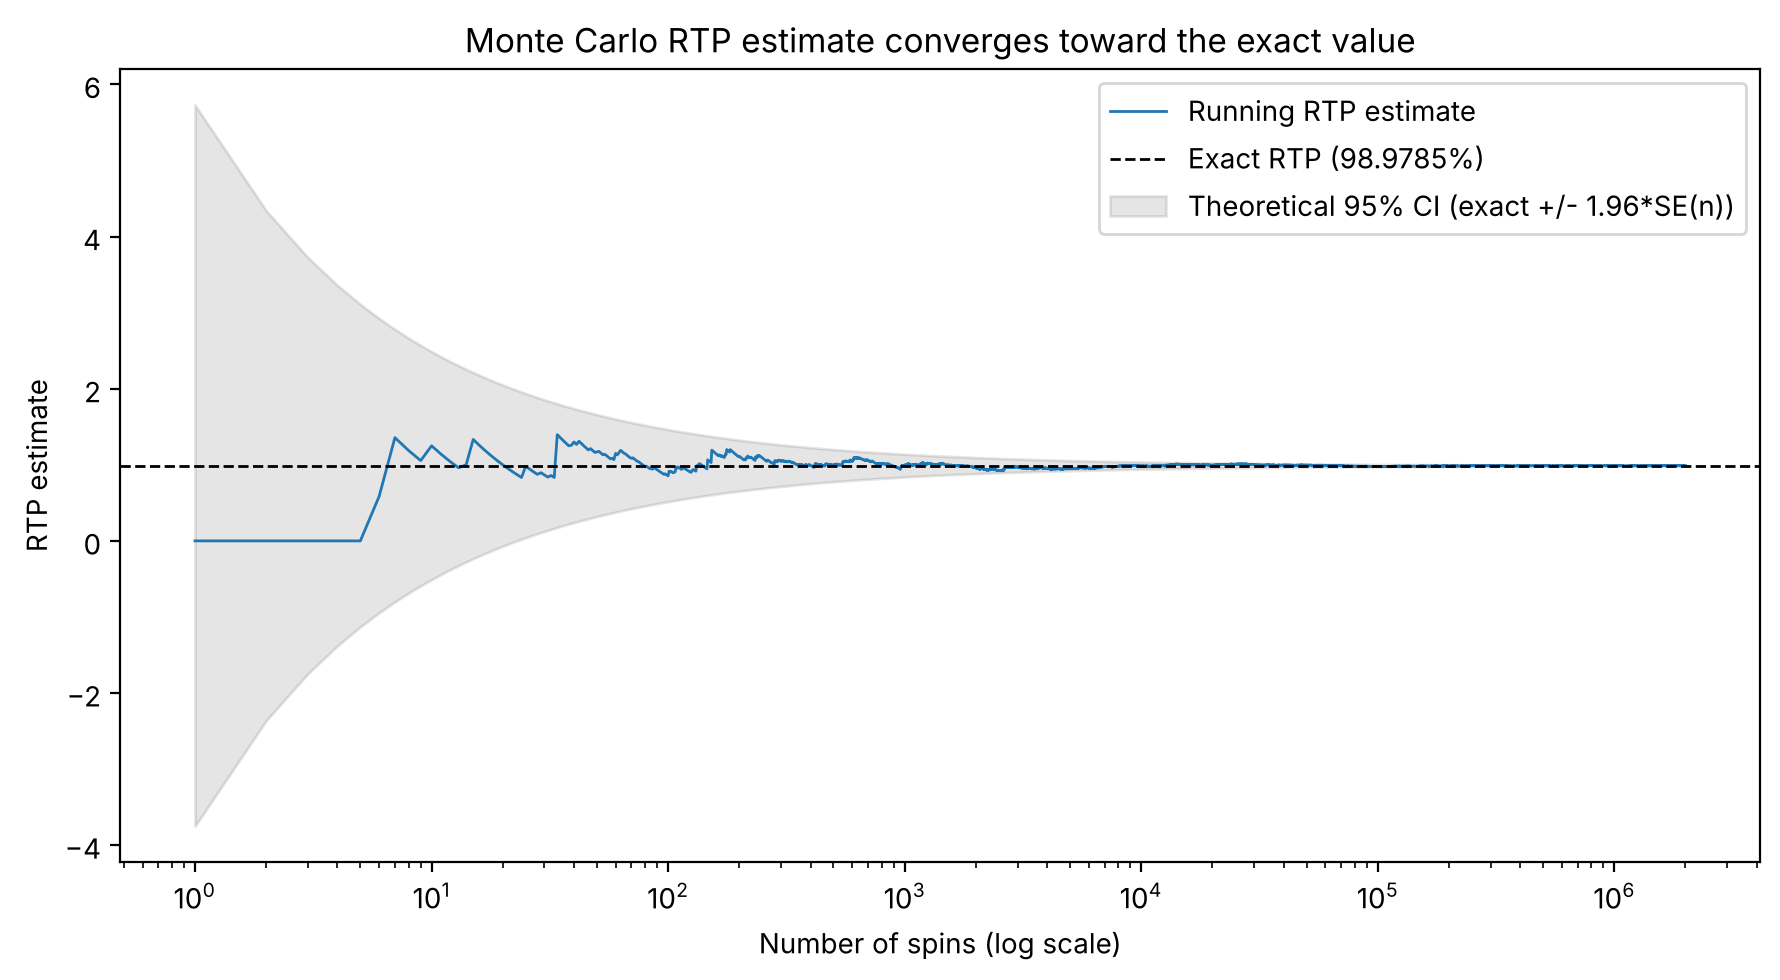

In [4]:
fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(spin_counts, cumulative_mean, color="#1f77b4", linewidth=1, label="Running RTP estimate")
ax.axhline(exact, color="black", linestyle="--", linewidth=1, label=f"Exact RTP ({exact:.4%})")
ax.fill_between(
    spin_counts,
    exact - 1.96 * standard_error,
    exact + 1.96 * standard_error,
    color="black",
    alpha=0.1,
    label="Theoretical 95% CI (exact +/- 1.96*SE(n))",
)

ax.set_xscale("log")
ax.set_xlabel("Number of spins (log scale)")
ax.set_ylabel("RTP estimate")
ax.set_title("Monte Carlo RTP estimate converges toward the exact value")
ax.legend()
plt.tight_layout()
plt.show()

## The first 2,000 spins

The log-scale plot above compresses the earliest spins. On a linear scale, the large early swings and how quickly they settle are much clearer.

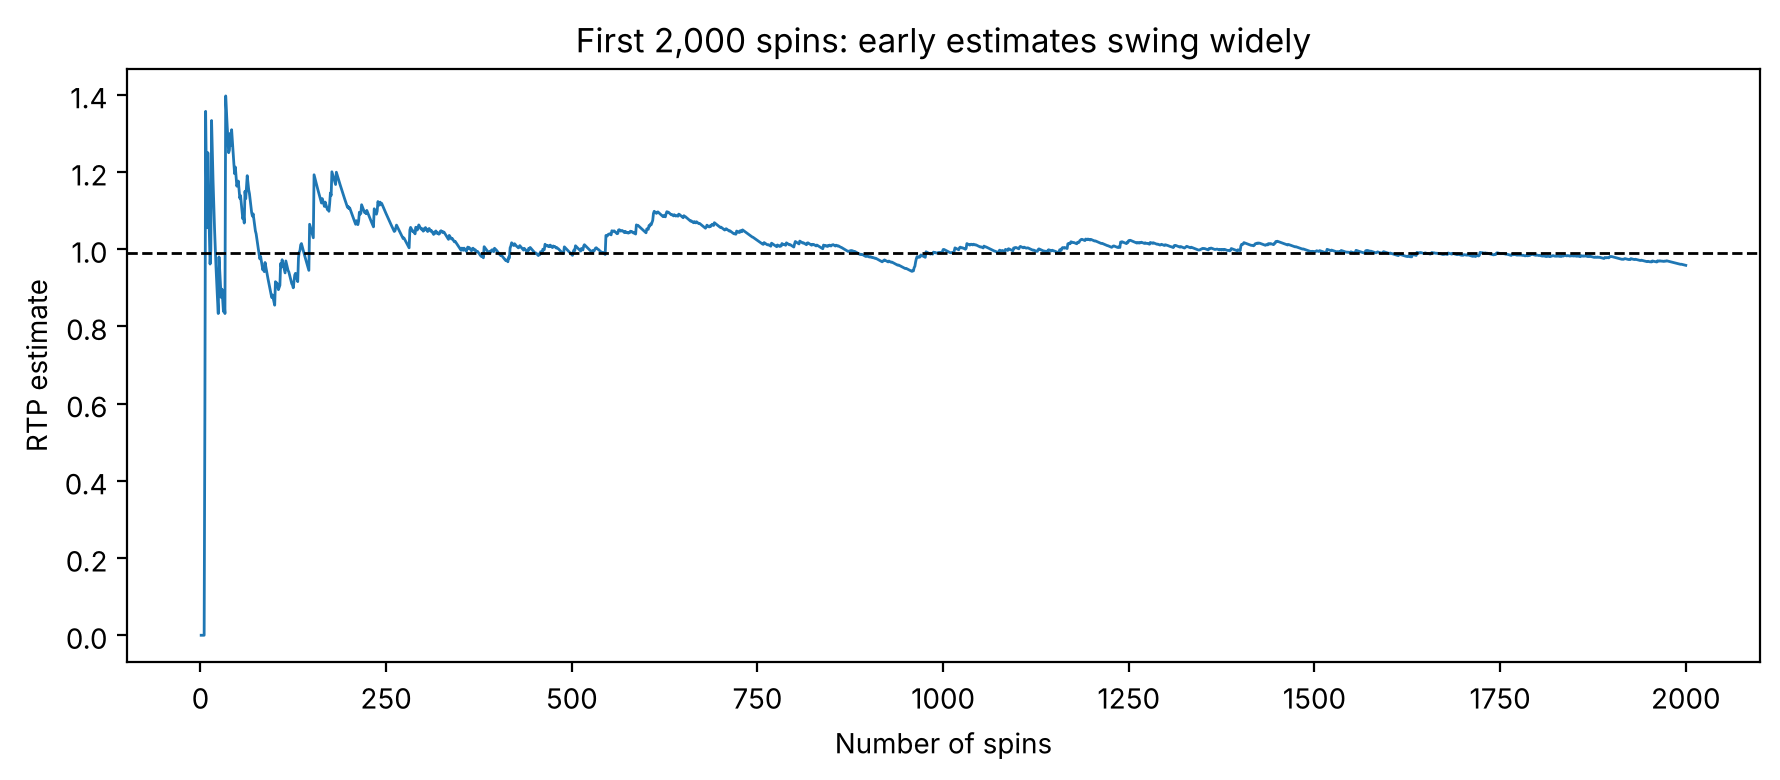

In [5]:
fig, ax = plt.subplots(figsize=(9, 4))
zoom_n = 2000

ax.plot(spin_counts[:zoom_n], cumulative_mean[:zoom_n], color="#1f77b4", linewidth=1)
ax.axhline(exact, color="black", linestyle="--", linewidth=1)
ax.set_xlabel("Number of spins")
ax.set_ylabel("RTP estimate")
ax.set_title("First 2,000 spins: early estimates swing widely")
plt.tight_layout()
plt.show()

## Takeaway

The plots show the `1/sqrt(n)` relationship reported in Phases 2 and 3, with error roughly halving for every 4x increase in spins: a wide, noisy funnel over the first few hundred spins narrows steadily and converges on the exact value from exhaustive enumeration. This is also why slot RTP certification reports confidence intervals rather than a single point estimate. Any finite simulation carries irreducible sampling noise, so the interval is the meaningful figure to report.